# Softmax
https://cme295.stanford.edu/syllabus/

https://youtu.be/eMlx5fFNoYc

https://youtu.be/kCc8FmEb1nY

https://youtu.be/OFS90-FX6pg


* The term "softmax" was coined in 1989 by British researcher John S. Bridle, though the mathematical formula itself was originally discovered in 1868 by Austrian physicist Ludwig Boltzmann.

* Instead of processing one word at a time, the model uses matrix multiplication to compute context for the entire sentence at once

**Transformer Attention Mechanism:** It updates your 768-number word vectors by letting every word look at other words for context. 

Using matrix multiplication, the model processes the entire sentence at once instead of word-by-word. Here is how the three parts of the slide connect:

### 1. The Inputs: Query ($Q$), Key ($K$), and Value ($V$)
At the bottom right, your 768-number embedding passes through three Linear layers. This creates three specialized vectors for every word:
* **Query ($Q$).** What the word is looking for (e.g., a verb searching for its subject).
* **Key ($K$).** What the word advertises about itself (e.g., "I am a noun").
* **Value ($V$).** The actual meaning the word passes along if matched.

---

### 2. Scaled Dot-Product Attention (Center Diagram)
The formula $\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$ maps to the center diagram from bottom to top:

1. **MatMul ($Q \cdot K^T$).** Multiplies every Query against every Key to score word relevance.
2. **Scale ($\div \sqrt{d_k}$).** Divides scores by the square root of the vector dimension ($d_k$) to stabilize learning.
3. **Mask (opt.).** Hides future words in models like GPT so they cannot look ahead when predicting the next word.
4. **SoftMax.** Turns raw scores into attention percentages (0 to 1) that total 100% (e.g., "bank" puts 85% focus on "river").
5. **MatMul ($\times V$).** Multiplies those percentages by the Value ($V$) vectors and adds them up. This creates a new, context-rich vector for each word.

---

### 3. Multi-Head Attention (Right Diagram)
Instead of running attention once, GPT-2 splits the 768 numbers across $h$ parallel heads. In GPT-2 Small, $h = 12$ heads each handle $64$ numbers ($768 \div 12$).

* **Why multiple heads?** Each head tracks a different relationship. One tracks grammar (subject-verb), another tracks pronouns ("it" $\rightarrow$ "the dog"), and another tracks nearby words.
* **Concat & Linear.** The model stitches all head outputs back together (Concat) into 768 numbers. A final Linear layer mixes these insights before sending them to the next layer.


---
---

## Step-by-step numerical example of $\text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$ using the phrase **"River bank"** and 4-dimensional vectors ($d_k = 4$).

### Step 0: Starting $Q$, $K$, and $V$ Vectors
To keep the math simple, we use 4 numbers per vector ($d_k = 4$) instead of 768:

* **Token 1: "River"**
  * $q_1 = [1, 0, 1, 0]$
  * $k_1 = [1, 1, 0, 0]$
  * $v_1 = [10, 0, 0, 0]$ *(carries "water" meaning)*
* **Token 2: "bank"**
  * $q_2 = [1, 1, 0, 0]$ *(looking for context: water or money?)*
  * $k_2 = [0, 0, 1, 1]$
  * $v_2 = [0, 0, 10, 0]$ *(carries generic "place" meaning)*

Stacked into $2 \times 4$ matrices:
$$Q=\begin{bmatrix}1&0&1&0\\ 1&1&0&0\end{bmatrix},\quad K=\begin{bmatrix}1&1&0&0\\ 0&0&1&1\end{bmatrix},\quad V=\begin{bmatrix}10&0&0&0\\ 0&0&10&0\end{bmatrix}$$

---

### Step 1: MatMul ($Q \cdot K^T$) — Similarity Scores
Multiply every Query row by every Key column to score word relevance:

* **"River" looking at both words:**
  * "River" $\rightarrow$ "River": $(1\times 1) + (0\times 1) + (1\times 0) + (0\times 0) = \mathbf{1}$
  * "River" $\rightarrow$ "bank": $(1\times 0) + (0\times 0) + (1\times 1) + (0\times 1) = \mathbf{1}$
* **"bank" looking at both words:**
  * "bank" $\rightarrow$ "River": $(1\times 1) + (1\times 1) + (0\times 0) + (0\times 0) = \mathbf{2}$ *(strong match!)*
  * "bank" $\rightarrow$ "bank": $(1\times 0) + (1\times 0) + (0\times 1) + (0\times 1) = \mathbf{0}$

$$QK^{T}=\begin{bmatrix}1&1\\ 2&0\end{bmatrix}$$

---

### Step 2: Scale ($\div \sqrt{d_{k}}$)
Since vector length $d_k = 4$, divide every score by $\sqrt{4} = \mathbf{2}$:

$$\frac{QK^{T}}{\sqrt{4}}=\begin{bmatrix}1/2&1/2\\ 2/2&0/2\end{bmatrix}=\begin{bmatrix}0.5&0.5\\ 1.0&0.0\end{bmatrix}$$

---

### Step 3: SoftMax — Attention Percentages
Apply $\text{softmax}(x_i) = \frac{e^{x_i}}{\sum e^{x_j}}$ to each row so weights total $1.0$ ($100\%$):

* **"River":** $[0.5, 0.5]$ are equal, giving **$50\%$** ($0.50$) to each word.
* **"bank":** $e^{1.0} \approx 2.72$ and $e^{0.0} = 1.00$ (sum $= 3.72$):
  * Focus on "River": $\frac{2.72}{3.72} \approx \mathbf{0.73}$ ($73\%$)
  * Focus on "bank": $\frac{1.00}{3.72} \approx \mathbf{0.27}$ ($27\%$)

$$\text{Attention Weights}=\begin{bmatrix}0.50&0.50\\ 0.73&0.27\end{bmatrix}$$

> **Takeaway:** "bank" shifts **73%** of its focus onto "River" to clarify its meaning.

---

### Step 4: Final MatMul ($\times V$) — Context-Aware Vectors
Blend the Value ($V$) vectors using each word's attention percentages:

* **New "River" vector:** $0.50 \times [10,0,0,0] + 0.50 \times [0,0,10,0] = \mathbf{[5.0, 0, 5.0, 0]}$
* **New "bank" vector:** $0.73 \times [10,0,0,0] + 0.27 \times [0,0,10,0] = \mathbf{[7.3, 0, 2.7, 0]}$

**Result:** "bank" started as a generic `[0, 0, 10, 0]`. After attention, it absorbed `7.3` of "River"'s water meaning—now representing a **riverbank** instead of a financial bank.


---
---

## How stuff works
This diagram shows how **Softmax** drives Self-Attention in the sentence *"The animal didn't cross the street because it was tired"*—specifically how **"it"** finds its meaning.

### How to Read This Diagram (Left to Right)

1. **Keys (Words in the Sentence):** The pronoun **"it"** sends out its Query to check every word in the sentence for context.
2. **Raw Similarity Scores ($\frac{QK^T}{\sqrt{d_k}}$):** Dot products generate raw scores. **"animal"** scores highest (`+4.1`), **"tired"** gets a moderate score (`+2.3`), and **"because"** scores negative (`-0.5`).
3. **Softmax Budget (The Attention Valve):** Softmax converts raw scores into percentages totaling 100%:
   * **Amplifies the winner:** **"animal"** jumps to **78%** of the attention budget.
   * **Mutes irrelevant words:** **"because"** (`-0.5`) and **"The"** (`+0.2`) drop to **1%–2%** so they don't add noise.
4. **Blended Output ($\times V$):** Thicker green arrows carry more information. **"animal"** pours **78%** of its Value vector into **"it"**, while **"tired"** adds **13%**. 

> **Result:** **"it"** is no longer a vague pronoun—its updated vector now mathematically represents **"tired animal."**
>

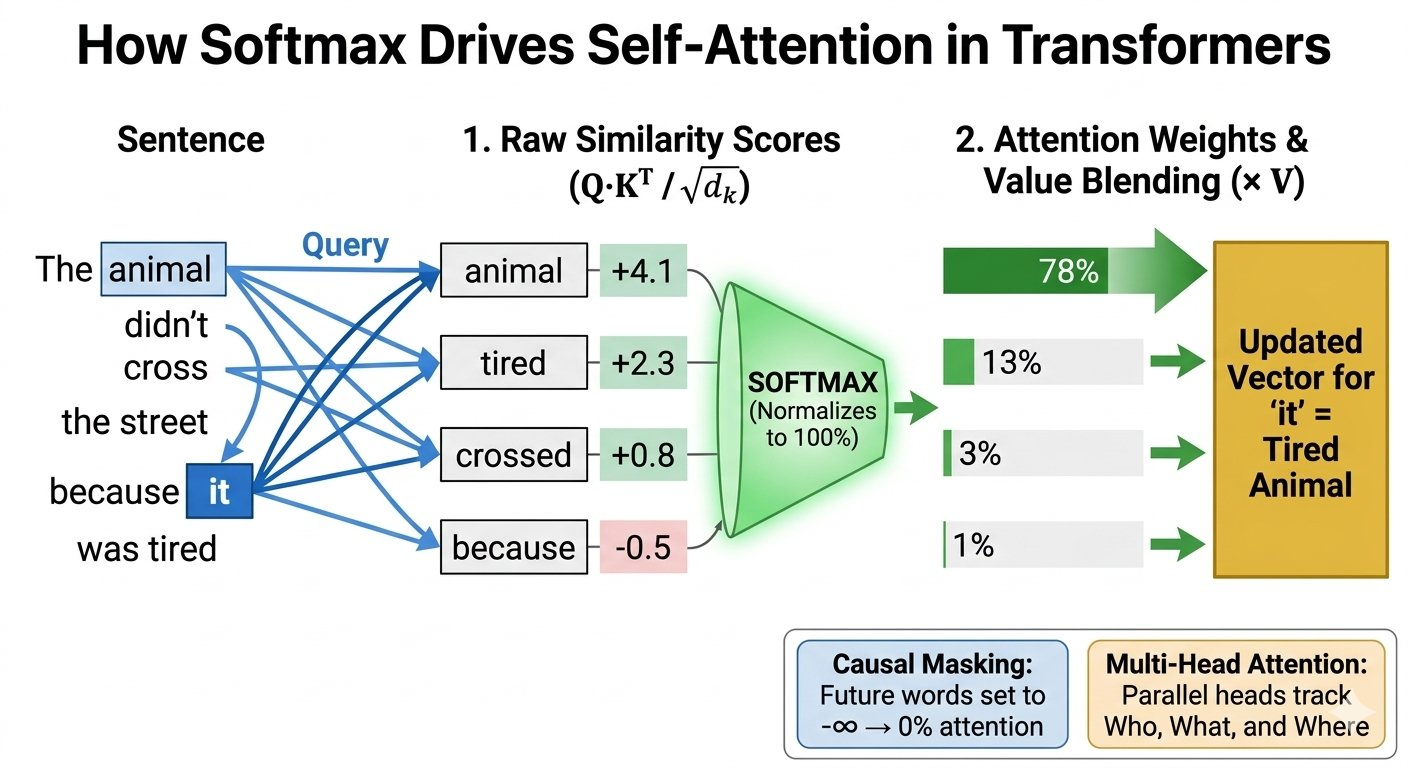


---
---

# BERT (Bidirectional Encoder Representations from Transformers):


* **BERT** Created by Google in 2018, reads text in both directions at once to deeply understand context.

* **GPT** uses the Transformer's **Decoder** (reading left-to-right to generate text), **BERT** uses the **Encoder** (reading the whole sentence at once to understand it).

---

### 1. What Makes BERT Special? ("Bidirectional" Reading)
Earlier models read strictly one way. BERT looks at words both before and after a target word simultaneously using Self-Attention without causal masking.

* **Example:** *"I went to the bank to deposit cash"* vs. *"I sat on the river bank."*
* By seeing *"deposit cash"* on the right and *"I went to"* on the left at the same time, BERT builds an accurate 768-number context vector for **"bank"**.

---

### 2. How BERT Was Trained (Two Pre-Training Tasks)
BERT learned language by playing two fill-in-the-blank games across Wikipedia and Books:

1. **Masked Language Modeling (MLM):** Google hid (`[MASK]`) **15%** of words in a sentence and trained BERT to guess them from surrounding context.
   * *Input:* `"The [MASK] barked loudly at the mailman."` $\rightarrow$ *Prediction:* `"dog"`
2. **Next Sentence Prediction (NSP):** BERT took two sentences (**A** and **B**) and predicted if **B** logically followed **A**, teaching it paragraph-level relationships.

---

### 3. BERT vs. GPT (At a Glance)

| Feature | BERT (Encoder-Only) | GPT (Decoder-Only) |
| :--- | :--- | :--- |
| **Reading Direction** | Bidirectional (left & right together) | Unidirectional (left-to-right, Causal Masking) |
| **Primary Superpower** | Understanding & extracting meaning | Generating & writing new text |
| **Vector Size (Base)** | 768 dimensions (12 layers, 12 heads) | 768 dimensions (GPT-2 Small: 12 layers, 12 heads) |
| **Best Use Cases** | Search ranking, sentiment analysis, spam filters, Q&A, document classification | Chatbots, coding assistants, creative writing, summarization |

---

### 4. Where You Encounter BERT Today
While chatbots like Gemini and ChatGPT focus on text generation, BERT—and faster variants like **RoBERTa**, **DistilBERT**, and **DeBERTa**—quietly powers billions of daily tasks:

* **Google Search** (decoding query intent)
* **Email spam filters** & customer support routing
* **Vector search embeddings** for Retrieval-Augmented Generation (RAG)


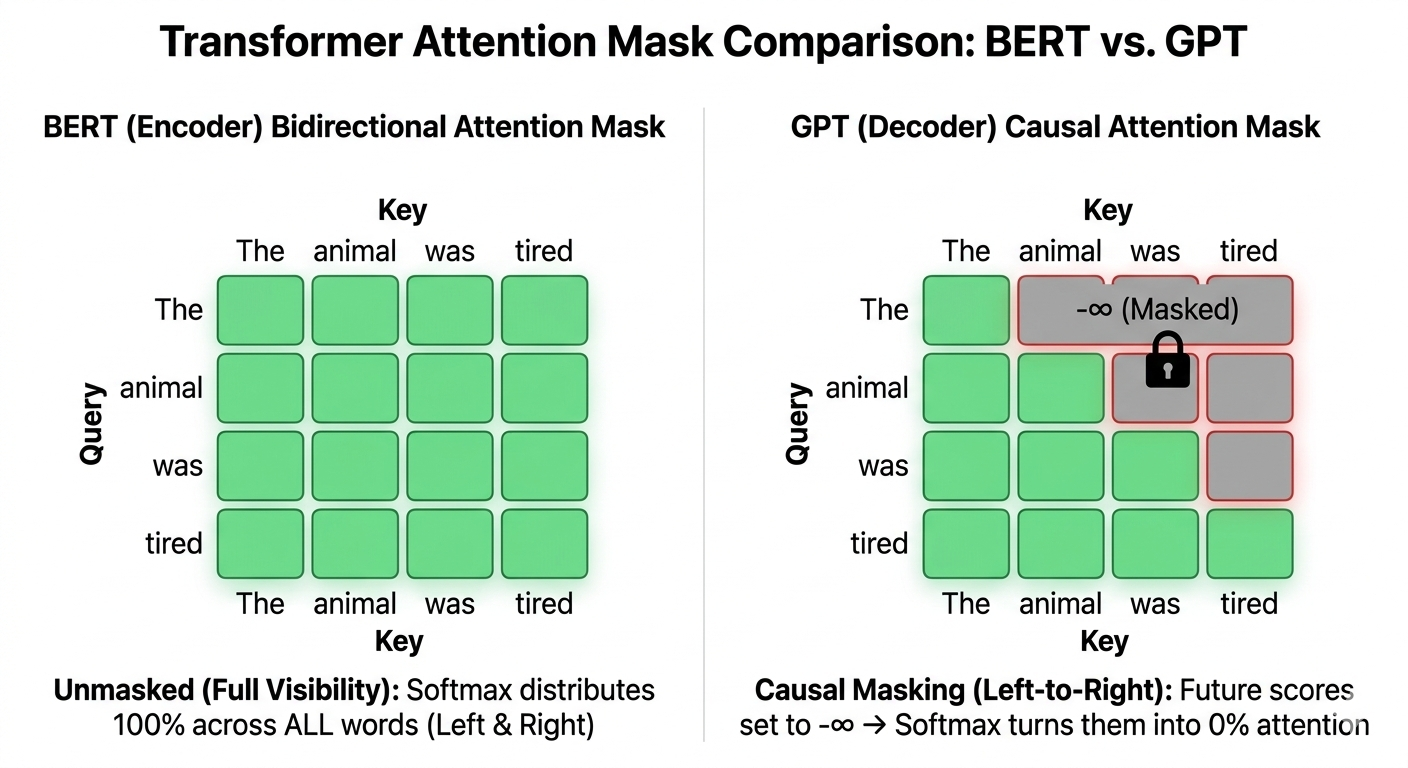